# Практика 7. Геометрия: преобразования, гомография, RANSAC

**Курс:** Анализ изображений

На практике 6 мы получили пары точек SIFT + ratio test. Сегодня из этих пар
соберём **одно преобразование плоскости** и применим его к изображению.

План:
- однородные координаты и иерархия преобразований;
- аффин по МНК и гомография методом DLT (с нормализацией Хартли);
- ошибка репроекции и RANSAC (сначала на прямой, затем на $H$);
- обратный warping, билинейная интерполяция, выравнивание документа;
- интеграция: локализация эталона контуром после RANSAC.

Данные только из `skimage.data` и NumPy — интернет не нужен.
Сначала сформулируйте ожидание, затем запускайте код. Заполняйте `TODO` по порядку. Чтобы перейти дальше до окончания задания, используйте реализацию, которую покажет преподаватель.


## 0. Импорты и вспомогательные функции


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

cv2.setNumThreads(1)
cv2.setRNGSeed(7)
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)


def show(*images, titles=None, figsize=(14, 4), cmaps=None):
    titles = titles or [""] * len(images)
    cmaps = cmaps or [None] * len(images)
    fig, axes = plt.subplots(1, len(images), figsize=figsize, squeeze=False)
    for ax, image, title, cmap in zip(axes[0], images, titles, cmaps):
        if image.ndim == 2:
            ax.imshow(image, cmap=cmap or "gray")
        else:
            ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")
    fig.tight_layout()
    plt.show()


def to_gray_u8(image):
    image = np.asarray(image)
    if image.ndim == 3:
        image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    if image.dtype != np.uint8:
        image = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return image


def apply_H(H, pts):
    """pts: (N,2) -> (N,2) after homography H."""
    pts = np.asarray(pts, dtype=np.float64)
    ones = np.ones((len(pts), 1))
    xy = (H @ np.hstack([pts, ones]).T).T
    w = xy[:, 2:3]
    # При w=0 точка не имеет конечных пиксельных координат.
    return np.divide(xy[:, :2], w, out=np.full_like(xy[:, :2], np.nan), where=w != 0)


OpenCV: 4.11.0
NumPy: 2.1.3


## 1. Мост с практики 6: пары есть — модели ещё нет

Повторим короткий фрагмент L06: эталон `page`, сцена с поворотом и масштабом,
SIFT + ratio. Геометрически верные пары проверяем по известной $H_{\mathrm{true}}$.

**Главный вопрос.** Даже при хорошем ratio остаётся доля выбросов. Как по сотне
пар найти одно $H$ и не дать выбросам испортить ответ?

**Предскажите.** Если $\varepsilon\approx 0.2$ и $s=4$, $p=0.99$, порядок $N$ — единицы, десятки или сотни? Вернёмся к расчёту в §8.


пар после ratio: 171 | геометрически верных: 155 (90.6%) | выбросов: 16


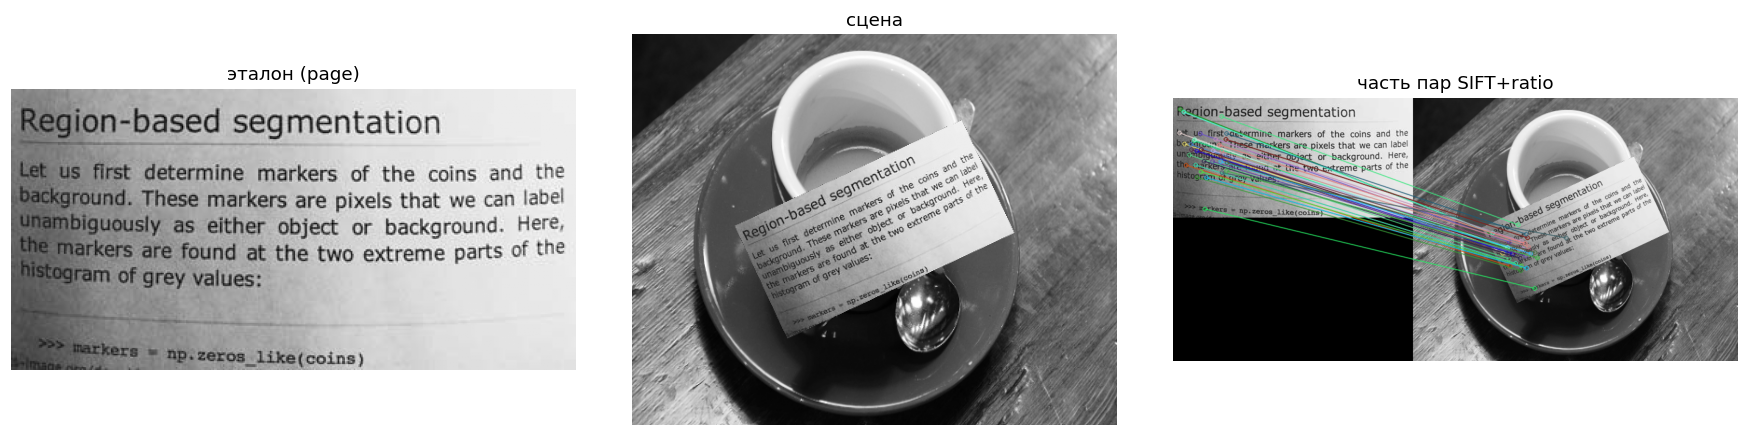

epsilon = 0.094 | N ≈ 5


In [3]:
# Синтетическая пара «эталон → сцена» с известным подобием (как в практике 6).
template = to_gray_u8(data.page())
h, w = template.shape
scene_h, scene_w = 420, 520
bg = to_gray_u8(data.coffee())
bg = cv2.resize(bg, (scene_w, scene_h))

angle, scale = 25.0, 0.7
A = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
A[:, 2] += np.array([scene_w / 2 - w / 2, scene_h / 2 - h / 2])
# Поднимем 2×3 до гомографии 3×3 (нижняя строка [0,0,1]).
H_true = np.vstack([A, [0.0, 0.0, 1.0]])

warped = cv2.warpAffine(template, A, (scene_w, scene_h))
mask = cv2.warpAffine(np.full_like(template, 255), A, (scene_w, scene_h), flags=cv2.INTER_NEAREST) > 0
scene = bg.copy()
scene[mask] = warped[mask]

sift = cv2.SIFT_create(nfeatures=800)
kp1, d1 = sift.detectAndCompute(template, None)
kp2, d2 = sift.detectAndCompute(scene, None)
bf = cv2.BFMatcher(cv2.NORM_L2)
knn = bf.knnMatch(d1, d2, k=2)
ratio = 0.75
good = [pair[0] for pair in knn
        if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance]
pts1 = np.float32([kp1[m.queryIdx].pt for m in good])
pts2 = np.float32([kp2[m.trainIdx].pt for m in good])

# Геометрическая проверка по известной истине (как в L06).
pred = apply_H(H_true, pts1)
geom_ok = np.linalg.norm(pred - pts2, axis=1) < 3.0
print(f"пар после ratio: {len(good)} | геометрически верных: {geom_ok.sum()} "
      f"({100 * geom_ok.mean():.1f}%) | выбросов: {(~geom_ok).sum()}")

vis = cv2.drawMatches(
    template, kp1, scene, kp2, good[:40], None,
    matchesThickness=1, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
)
show(template, scene, cv2.cvtColor(vis, cv2.COLOR_BGR2RGB),
     titles=["эталон (page)", "сцена", "часть пар SIFT+ratio"], figsize=(16, 4))

epsilon = 1.0 - float(geom_ok.mean())
p_success, s = 0.99, 4
q_clean = (1.0 - epsilon) ** s
if q_clean == 1.0:
    N_needed = 1
elif q_clean == 0.0:
    N_needed = np.inf
else:
    N_needed = int(np.ceil(np.log1p(-p_success) / np.log1p(-q_clean)))
print("epsilon =", round(epsilon, 3), "| N ≈", N_needed)


## 2. Однородные координаты и евклидово преобразование

Точке $(x,y)$ сопоставляем $(x,y,1)\sim(\lambda x,\lambda y,\lambda)$. Тогда сдвиг и поворот —
умножение на матрицу $3\times 3$:
$$
\begin{pmatrix}x'\\y'\\1\end{pmatrix}
=
\begin{pmatrix}\cos\theta&-\sin\theta&t_x\\\sin\theta&\cos\theta&t_y\\0&0&1\end{pmatrix}
\begin{pmatrix}x\\y\\1\end{pmatrix}.
$$
3 степени свободы; сохраняются длины и углы.

**Посчитайте.** Куда перейдёт $(2,1)$ при $\theta=90^\circ$, $t=(5,0)$? Что произойдет с длинами двух точек.


In [4]:
def euclidean_H(theta_deg, tx, ty):
    th = np.deg2rad(theta_deg)
    c, s = np.cos(th), np.sin(th)
    return np.array([[c, -s, tx], [s, c, ty], [0.0, 0.0, 1.0]], dtype=np.float64)


H_demo = euclidean_H(90, 5, 0)
pts = np.array([[2.0, 1.0], [0.0, 0.0], [3.0, 4.0]])
print("H =\n", np.round(H_demo, 3))
print("образы точек:\n", apply_H(H_demo, pts))

# Сравниваем попарные расстояния: обе точки переносятся.
src = pts - pts[1]
dst = apply_H(H_demo, pts) - apply_H(H_demo, pts[1:2])
print("длины до:", np.round(np.linalg.norm(src, axis=1), 3))
print("длины после:", np.round(np.linalg.norm(dst, axis=1), 3))

H =
 [[ 0. -1.  5.]
 [ 1.  0.  0.]
 [ 0.  0.  1.]]
образы точек:
 [[4. 2.]
 [5. 0.]
 [1. 3.]]
длины до: [2.236 0.    5.   ]
длины после: [2.236 0.    5.   ]


## 3. Иерархия: подобие → аффин → гомография

Каждое следующее включает предыдущее:

- сдвиг — 2 ст. свободы, мин. 1 пара; сохраняет всё, кроме положения;
- евклидово — 3 / 2; длины и углы;
- подобие — 4 / 2; углы и отношения длин;
- аффинное — 6 / 3; параллельность;
- гомография — 8 / 4; прямые линии.

Гомография точно связывает виды **одной плоскости** или изображения при **чистом повороте камеры вокруг оптического центра**. При переносе камеры объекты на разных глубинах могут смещаться по-разному.

**Предскажите.** Какое преобразование переведёт квадрат в трапецию с непараллельными боковыми?


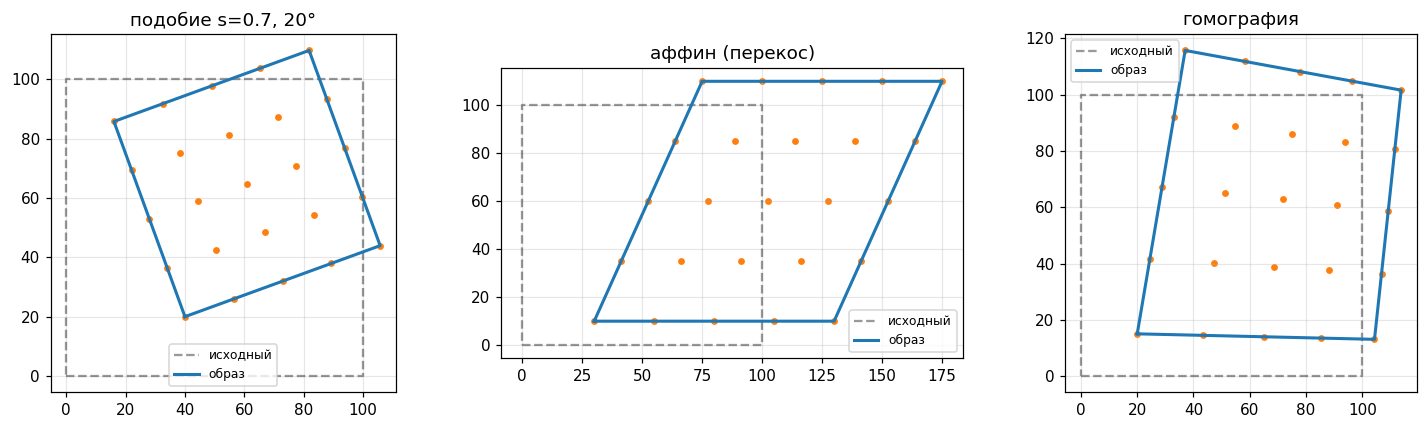

ст. свободы: сдвиг 2 | евклидово 3 | подобие 4 | аффин 6 | гомография 8
мин. пар точек:     1 |          2 |         2 |       3 |           4


In [5]:
def similarity_H(scale, theta_deg, tx, ty):
    th = np.deg2rad(theta_deg)
    c, s = np.cos(th), np.sin(th)
    return np.array([[scale * c, -scale * s, tx],
                     [scale * s, scale * c, ty],
                     [0.0, 0.0, 1.0]], dtype=np.float64)


def affine_H(a11, a12, a21, a22, tx, ty):
    return np.array([[a11, a12, tx], [a21, a22, ty], [0.0, 0.0, 1.0]], dtype=np.float64)


# Квадрат и сетка для наглядности.
square = np.array([[0, 0], [100, 0], [100, 100], [0, 100], [0, 0]], dtype=np.float64)
grid = np.array([[x, y] for y in range(0, 101, 25) for x in range(0, 101, 25)], dtype=np.float64)

Hs = {
    "подобие s=0.7, 20°": similarity_H(0.7, 20, 40, 20),
    "аффин (перекос)": affine_H(1.0, 0.45, 0.0, 1.0, 30, 10),
    "гомография": np.array([[1.0, 0.2, 20], [0.0, 1.1, 15], [0.0015, 0.0008, 1.0]]),
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, H) in zip(axes, Hs.items()):
    sq = apply_H(H, square)
    gd = apply_H(H, grid)
    ax.plot(square[:, 0], square[:, 1], "k--", alpha=0.4, label="исходный")
    ax.plot(sq[:, 0], sq[:, 1], "C0-", lw=2, label="образ")
    ax.scatter(gd[:, 0], gd[:, 1], s=12, c="C1")
    ax.set_title(name)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print("ст. свободы: сдвиг 2 | евклидово 3 | подобие 4 | аффин 6 | гомография 8")
print("мин. пар точек:     1 |          2 |         2 |       3 |           4")

## 4. Аффинное преобразование по МНК

Каждая пара даёт 2 уравнения на 6 неизвестных $(a_{11},a_{12},t_x,a_{21},a_{22},t_y)$.
При $n>3$ система переопределена — берём $\hat a=\arg\min\|Ma-b\|_2$ через `np.linalg.lstsq`.

**Задание.** Реализуйте `estimate_affine_lstsq`.


In [6]:
def estimate_affine_lstsq(pts_src, pts_dst):
    """Оцените аффин 2×3 методом наименьших квадратов."""
    pts_src = np.asarray(pts_src, dtype=np.float64)
    pts_dst = np.asarray(pts_dst, dtype=np.float64)
    n = len(pts_src)
    M = np.zeros((2 * n, 6), dtype=np.float64)
    b = np.zeros(2 * n, dtype=np.float64)
    for i, ((x, y), (xp, yp)) in enumerate(zip(pts_src, pts_dst)):
        M[2 * i] = [x, y, 1, 0, 0, 0]
        M[2 * i + 1] = [0, 0, 0, x, y, 1]
        b[2 * i] = xp
        b[2 * i + 1] = yp
    params, *_ = np.linalg.lstsq(M, b, rcond=None)
    return params.reshape(2, 3)


rng = np.random.default_rng(0)
A_true = np.array([[1.2, 0.3, 10.0], [-0.2, 0.9, 20.0]])
corners = np.array([[0, 0], [100, 0], [0, 100], [100, 100]], dtype=np.float64)
dst = (A_true @ np.hstack([corners, np.ones((4, 1))]).T).T
dst_noisy = dst + rng.normal(0, 0.5, dst.shape)

A_hat = estimate_affine_lstsq(corners, dst_noisy)
print("A_true:\n", A_true)
print("A_hat:\n", np.round(A_hat, 3))
print("ср. |ошибка параметров|:", np.mean(np.abs(A_hat - A_true)))

A_true:
 [[ 1.2  0.3 10. ]
 [-0.2  0.9 20. ]]
A_hat:
 [[ 1.206  0.3    9.897]
 [-0.198  0.903 19.89 ]]
ср. |ошибка параметров|: 0.0372761398234698


## 5. Гомография: DLT и нормализация Хартли

Из $x'=\frac{h_1^\top x}{h_3^\top x}$ после умножения на знаменатель получаем линейные
уравнения на $h$ (9 чисел, 8 степеней свободы). Решение: SVD, $h$ — последняя строка `Vt` в NumPy.
При четырёх парах $A$ имеет форму $8\times9$. Нужен полный `Vt` размера $9\times9$,
чтобы получить направление из ядра $A$.

Нормализация: сдвинуть точки к нулю и масштабировать среднее расстояние до $\sqrt{2}$,
затем $H=T'^{-1}\tilde H T$. Так координаты и их произведения в $A$ оказываются ближе по масштабу.

**Задание.** Реализуйте `normalize_points` и `dlt_homography`. Проверьте пример квадрат→трапеция.


In [8]:
from itertools import combinations


def normalize_points(pts):
    """Нормализация Хартли: центрировать и масштабировать ср. расстояние до sqrt(2)."""
    pts = np.asarray(pts, dtype=np.float64)
    c = pts.mean(axis=0)
    dist = np.linalg.norm(pts - c, axis=1).mean()
    if dist == 0:
        raise np.linalg.LinAlgError('Все точки совпадают.')
    s = np.sqrt(2.0) / dist
    T = np.array([[s, 0, -s * c[0]], [0, s, -s * c[1]], [0, 0, 1.0]], dtype=np.float64)
    pts_h = np.hstack([pts, np.ones((len(pts), 1))])
    pts_n = (T @ pts_h.T).T
    return pts_n[:, :2] / pts_n[:, 2:3], T


def dlt_homography(pts_src, pts_dst, normalize=True):
    """Оценка гомографии DLT. Минимум 4 пары."""
    pts_src = np.asarray(pts_src, dtype=np.float64)
    pts_dst = np.asarray(pts_dst, dtype=np.float64)
    n = len(pts_src)
    if pts_src.shape != (n, 2) or pts_dst.shape != (n, 2) or n < 4:
        raise ValueError('Нужны два массива (N, 2) и минимум четыре пары.')
    if normalize:
        src_n, T = normalize_points(pts_src)
        dst_n, Tp = normalize_points(pts_dst)
    else:
        src_n, dst_n = pts_src, pts_dst
        T = Tp = np.eye(3)

    if n == 4:
        for points in (src_n, dst_n):
            points_h = np.column_stack([points, np.ones(n)])
            for triple in combinations(range(n), 3):
                if np.linalg.matrix_rank(points_h[list(triple)]) < 3:
                    raise np.linalg.LinAlgError('Три точки выборки коллинеарны.')

    A = np.zeros((2 * n, 9), dtype=np.float64)
    for i, ((x, y), (xp, yp)) in enumerate(zip(src_n, dst_n)):
        A[2 * i] = [-x, -y, -1, 0, 0, 0, xp * x, xp * y, xp]
        A[2 * i + 1] = [0, 0, 0, -x, -y, -1, yp * x, yp * y, yp]
    # При 8×9 сокращённое SVD потеряло бы вектор ядра.
    _, singular_values, Vt = np.linalg.svd(A, full_matrices=A.shape[0] < A.shape[1])
    tol = max(A.shape) * np.finfo(A.dtype).eps * singular_values[0]
    if np.count_nonzero(singular_values > tol) < 8:
        raise np.linalg.LinAlgError('Недостаточно независимых уравнений DLT.')
    H = Vt[-1].reshape(3, 3)
    if normalize:
        H = np.linalg.inv(Tp) @ H @ T
    # H[2, 2] может быть нулём у корректной гомографии.
    if abs(H[2, 2]) > np.finfo(H.dtype).eps * np.linalg.norm(H):
        H = H / H[2, 2]
    return H


# Квадрат → трапеция из лекции.
src_sq = np.array([[0, 0], [1, 0], [1, 1], [0, 1]], dtype=np.float64)
dst_trap = np.array([[0, 0], [4, 0], [3, 2], [1, 2]], dtype=np.float64)
H_trap = dlt_homography(src_sq, dst_trap, normalize=False)
print("H (трапеция):\n", np.round(H_trap, 4))
print("проверка (1,1) ->", apply_H(H_trap, [[1.0, 1.0]]))


H (трапеция):
 [[ 4.  2.  0.]
 [-0.  4. -0.]
 [ 0.  1.  1.]]
проверка (1,1) -> [[3. 2.]]


## 6. Ошибка репроекции

$$
e_i=\bigl\|x'_i-\pi(Hx_i)\bigr\|,\qquad \pi(x,y,w)=\Bigl(\frac{x}{w},\frac{y}{w}\Bigr).
$$
DLT минимизирует алгебраическую невязку $\|Ah\|$ при $\|h\|=1$. Для сравнения моделей измеряем геометрическое отклонение в пикселях. На одной выборке медиана может вести себя по-разному.

**Задание.** Реализуйте `reprojection_errors` и сравните медиану с/без нормализации.


In [9]:
def reprojection_errors(H, pts_src, pts_dst):
    """Верните массив e_i = ||x'_i - π(H x_i)|| для каждой пары."""
    pred = apply_H(H, pts_src)
    errors = np.linalg.norm(pred - np.asarray(pts_dst, dtype=np.float64), axis=1)
    return np.where(np.isfinite(errors), errors, np.inf)


# Пиксельные точки + шум: без нормализации vs с нормализацией.
rng = np.random.default_rng(1)
H_pix = np.array([[1.2, 0.15, 80.0],
                  [0.05, 1.1, 40.0],
                  [0.0004, 0.0002, 1.0]])
src_pix = rng.uniform([100, 80], [500, 360], size=(20, 2))
dst_pix = apply_H(H_pix, src_pix) + rng.normal(0, 0.4, size=src_pix.shape)

H_raw = dlt_homography(src_pix, dst_pix, normalize=False)
H_norm = dlt_homography(src_pix, dst_pix, normalize=True)
err_raw = reprojection_errors(H_raw, src_pix, dst_pix)
err_norm = reprojection_errors(H_norm, src_pix, dst_pix)
print("медиана ошибки без нормализации:", float(np.median(err_raw)))
print("медиана ошибки с нормализацией:  ", float(np.median(err_norm)))


медиана ошибки без нормализации: 0.4058009194965535
медиана ошибки с нормализацией:   0.3725445959795391


## 7. RANSAC на прямой: почему МНК не выдерживает выбросов

Выброс с ошибкой 5 весит в $\sum e_i^2$ как 25 точек с ошибкой 1.
В этой задаче используем вертикальную невязку $|y-(ax+b)|$. RANSAC: многократно берём минимальную выборку → модель → голосуем порогом $\tau$ → уточняем по inliers.

**Задание.** Реализуйте `ransac_line` и сравните с МНК на смеси 40 inliers + 20 outliers.


МНК:     y = 0.170x + 2.973
RANSAC:  y = 0.523x + 0.881 | inliers=42


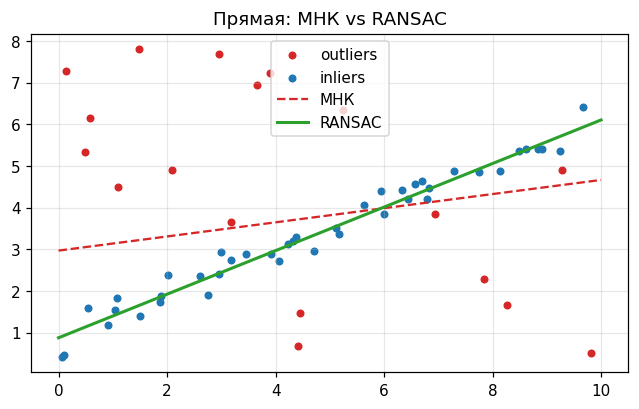

In [10]:
def ransac_line(xy, tau=0.6, n_iter=200, seed=0):
    """RANSAC для прямой y = ax + b по точкам (N,2)."""
    rng = np.random.default_rng(seed)
    xy = np.asarray(xy, dtype=np.float64)
    best_mask = np.zeros(len(xy), dtype=bool)
    for _ in range(n_iter):
        i0, i1 = rng.choice(len(xy), size=2, replace=False)
        (x0, y0), (x1, y1) = xy[i0], xy[i1]
        if abs(x1 - x0) < 1e-9:
            continue
        a = (y1 - y0) / (x1 - x0)
        b = y0 - a * x0
        resid = np.abs(xy[:, 1] - (a * xy[:, 0] + b))
        mask = resid < tau
        if mask.sum() > best_mask.sum():
            best_mask = mask
    if best_mask.sum() < 2:
        raise ValueError("Не найдена прямая с поддержкой хотя бы из двух точек.")
    X = np.column_stack([xy[best_mask, 0], np.ones(best_mask.sum())])
    a, b = np.linalg.lstsq(X, xy[best_mask, 1], rcond=None)[0]
    mask = np.abs(xy[:, 1] - (a * xy[:, 0] + b)) < tau
    return float(a), float(b), mask


rng = np.random.default_rng(2)
x = rng.uniform(0, 10, 40)
y = 0.5 * x + 1.0 + rng.normal(0, 0.25, 40)
out_x = rng.uniform(0, 10, 20)
out_y = rng.uniform(0, 8, 20)
xy = np.column_stack([np.concatenate([x, out_x]), np.concatenate([y, out_y])])

X = np.column_stack([xy[:, 0], np.ones(len(xy))])
a_ls, b_ls = np.linalg.lstsq(X, xy[:, 1], rcond=None)[0]
a_r, b_r, mask = ransac_line(xy)
print(f"МНК:     y = {a_ls:.3f}x + {b_ls:.3f}")
print(f"RANSAC:  y = {a_r:.3f}x + {b_r:.3f} | inliers={mask.sum()}")

xs = np.linspace(0, 10, 100)
plt.figure(figsize=(7, 4))
plt.scatter(xy[~mask, 0], xy[~mask, 1], c="C3", s=18, label="outliers")
plt.scatter(xy[mask, 0], xy[mask, 1], c="C0", s=18, label="inliers")
plt.plot(xs, a_ls * xs + b_ls, "C3--", label="МНК")
plt.plot(xs, a_r * xs + b_r, "C2-", lw=2, label="RANSAC")
plt.legend(); plt.grid(True, alpha=0.3); plt.title("Прямая: МНК vs RANSAC"); plt.show()


## 8. RANSAC для гомографии

Алгоритм: $s=4$ пары → DLT → inliers с $e_i<\tau$ (часто 3 пикс.) → уточнение DLT+normalize по inliers.
Оценка числа итераций $N=\left\lceil\ln(1-p)/\ln\bigl(1-(1-\varepsilon)^s\bigr)\right\rceil$. $p$ — вероятность хотя бы одной чистой выборки, $\varepsilon$ — доля выбросов.

**Задание.** Реализуйте `ransac_homography`. Добавьте 25 случайных выбросов к парам из §1 и сравните
контур эталона: DLT по всем vs RANSAC.


DLT по всем: медиана на контрольных парах = 69.70 px
RANSAC: inliers=155/196, медиана на контрольных парах = 0.12 px


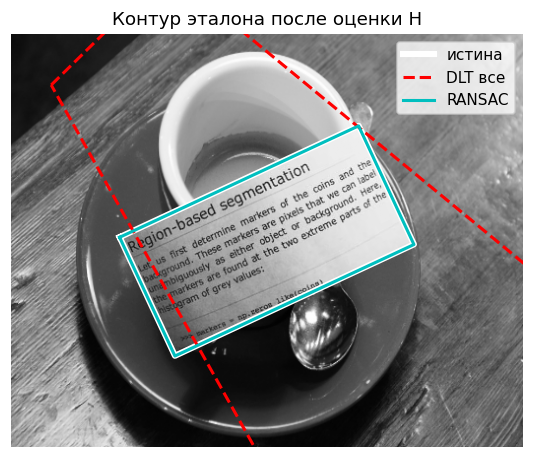

In [11]:
def ransac_homography(pts_src, pts_dst, tau=3.0, n_iter=500, seed=7):
    """RANSAC для гомографии: выборка из 4 пар → DLT → inliers по ошибке репроекции."""
    pts_src = np.asarray(pts_src, dtype=np.float64)
    pts_dst = np.asarray(pts_dst, dtype=np.float64)
    rng = np.random.default_rng(seed)
    if len(pts_src) < 4 or pts_dst.shape != pts_src.shape:
        raise ValueError("Для RANSAC нужны минимум четыре соответствия.")
    best_mask = np.zeros(len(pts_src), dtype=bool)
    best_H = None
    for _ in range(n_iter):
        idx = rng.choice(len(pts_src), size=4, replace=False)
        try:
            # DLT проверяет коллинеарность троек в обеих частях выборки.
            Hk = dlt_homography(pts_src[idx], pts_dst[idx], normalize=True)
        except np.linalg.LinAlgError:
            continue
        err = reprojection_errors(Hk, pts_src, pts_dst)
        mask = err < tau
        if mask.sum() > best_mask.sum():
            best_mask = mask
            best_H = Hk
    if best_mask.sum() < 4:
        raise ValueError("Не найдена гомография с поддержкой хотя бы из четырёх пар.")
    try:
        H_refined = dlt_homography(pts_src[best_mask], pts_dst[best_mask], normalize=True)
    except np.linalg.LinAlgError:
        return best_H, best_mask
    refined_mask = reprojection_errors(H_refined, pts_src, pts_dst) < tau
    if refined_mask.sum() >= 4:
        return H_refined, refined_mask
    return best_H, best_mask


# Добавим искусственные выбросы к парам из раздела 1.
n_out = 25
rng = np.random.default_rng(3)
out1 = rng.uniform([0, 0], [w, h], size=(n_out, 2)).astype(np.float32)
out2 = rng.uniform([0, 0], [scene_w, scene_h], size=(n_out, 2)).astype(np.float32)
pts1_all = np.vstack([pts1, out1])
pts2_all = np.vstack([pts2, out2])

H_all = dlt_homography(pts1_all, pts2_all, normalize=True)
H_ran, inliers = ransac_homography(pts1_all, pts2_all, tau=3.0)
# Обе оценки проверяем на одном наборе пар, помеченных через H_true в §1.
err_all = reprojection_errors(H_all, pts1[geom_ok], pts2[geom_ok])
err_ran = reprojection_errors(H_ran, pts1[geom_ok], pts2[geom_ok])
print(f"DLT по всем: медиана на контрольных парах = {np.median(err_all):.2f} px")
print(f"RANSAC: inliers={inliers.sum()}/{len(inliers)}, медиана на контрольных парах = {np.median(err_ran):.2f} px")

contour = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], dtype=np.float64)
c_true = apply_H(H_true, contour)
c_all = apply_H(H_all, contour)
c_ran = apply_H(H_ran, contour)
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(scene, cmap="gray")
ax.plot(*np.vstack([c_true, c_true[:1]]).T, "w-", lw=4, label="истина")
ax.plot(*np.vstack([c_all, c_all[:1]]).T, "r--", lw=2, label="DLT все")
ax.plot(*np.vstack([c_ran, c_ran[:1]]).T, "c-", lw=2, label="RANSAC")
ax.set_xlim(-0.5, scene_w - 0.5)
ax.set_ylim(scene_h - 0.5, -0.5)
ax.legend(); ax.set_title("Контур эталона после оценки H"); ax.axis("off"); plt.show()


## 9. Обратный warping и билинейная интерполяция

Прямое отображение оставляет дыры при увеличении. Обратное:
$$
J(x')=I\bigl(\pi(H^{-1}x')\bigr).
$$
Билинейная: $I(a,b)\approx(1-a)(1-b)I_{00}+a(1-b)I_{10}+(1-a)b I_{01}+ab I_{11}$.

**Задание.** Реализуйте `bilinear_sample` и `warp_inverse`. Выпрямите синтетический документ по 4 углам.
Проверьте пример лекции: $I\in\{10,20,30,60\}$, $a=0.25$, $b=0.5$ → 25.


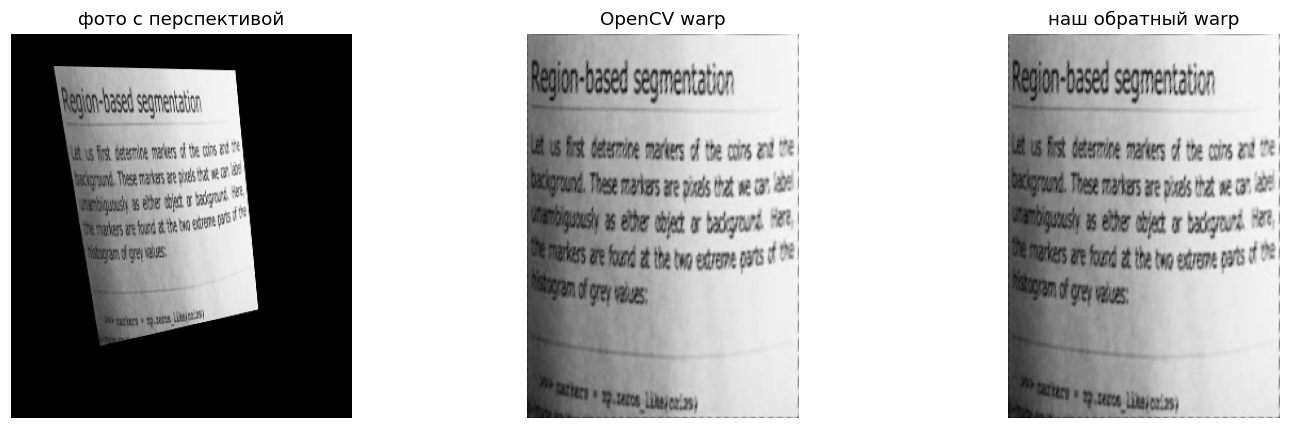

билинейная проверка: 25.0 (ожидается 25)


In [12]:
def bilinear_sample(image, x, y):
    """Билинейная выборка яркости в дробной точке (x, y). Вне кадра — 0."""
    image = np.asarray(image, dtype=np.float64)
    h, w = image.shape[:2]
    if x < 0 or y < 0 or x >= w - 1 or y >= h - 1:
        return 0.0
    x0 = int(np.floor(x)); y0 = int(np.floor(y))
    a = x - x0; b = y - y0
    I00 = image[y0, x0]; I10 = image[y0, x0 + 1]
    I01 = image[y0 + 1, x0]; I11 = image[y0 + 1, x0 + 1]
    return (1 - a) * (1 - b) * I00 + a * (1 - b) * I10 + (1 - a) * b * I01 + a * b * I11


def warp_inverse(image, H, out_shape):
    """Обратное отображение: для каждого пикселя результата p' берём I(π(H^{-1} p'))."""
    image = np.asarray(image, dtype=np.float64)
    H_inv = np.linalg.inv(H)
    hh, ww = out_shape
    yy, xx = np.mgrid[0:hh, 0:ww].astype(np.float64)
    dest = np.column_stack([xx.ravel(), yy.ravel()])
    src = apply_H(H_inv, dest)
    x, y = src[:, 0], src[:, 1]
    out = np.zeros(hh * ww, dtype=np.float64)
    h, w = image.shape[:2]
    valid = (x >= 0) & (y >= 0) & (x < w - 1) & (y < h - 1)
    x0 = np.floor(x[valid]).astype(int)
    y0 = np.floor(y[valid]).astype(int)
    a = x[valid] - x0
    b = y[valid] - y0
    I00 = image[y0, x0]; I10 = image[y0, x0 + 1]
    I01 = image[y0 + 1, x0]; I11 = image[y0 + 1, x0 + 1]
    out[valid] = (1 - a) * (1 - b) * I00 + a * (1 - b) * I10 + (1 - a) * b * I01 + a * b * I11
    return out.reshape(hh, ww)


doc = to_gray_u8(data.page())
doc = cv2.resize(doc, (210, 297))
H_persp = np.array([[1.0, 0.18, 40.0],
                    [0.05, 1.0, 30.0],
                    [0.0009, 0.0004, 1.0]])
photo = cv2.warpPerspective(doc, H_persp, (320, 360))

doc_h, doc_w = doc.shape
corners_src = np.array([[0, 0], [doc_w - 1, 0], [doc_w - 1, doc_h - 1], [0, doc_h - 1]], dtype=np.float64)
corners_photo = apply_H(H_persp, corners_src)
corners_dst = corners_src.copy()
H_rect = dlt_homography(corners_photo, corners_dst, normalize=True)

rect_cv = cv2.warpPerspective(photo, H_rect, (210, 297))
rect_ours = warp_inverse(photo, H_rect, (297, 210))
show(photo, rect_cv, rect_ours.astype(np.uint8),
     titles=["фото с перспективой", "OpenCV warp", "наш обратный warp"], figsize=(14, 4))

patch = np.array([[10.0, 20.0], [30.0, 60.0]])
val = bilinear_sample(patch, 0.25, 0.5)
print("билинейная проверка:", val, "(ожидается 25)")


## 10. Мини-задача: локализация эталона (L06 → L07)

Соберите конвейер: SIFT → ratio → RANSAC-гомография → нарисуйте контур эталона на сцене.
Сравните свой контур и контур `cv2.findHomography(..., cv2.RANSAC)` по ошибке четырёх углов относительно синтетической истины.

Это и есть недостающий кусок практики 6: не только «плакат есть», но и **где именно**.


пар: 171 | inliers: 155


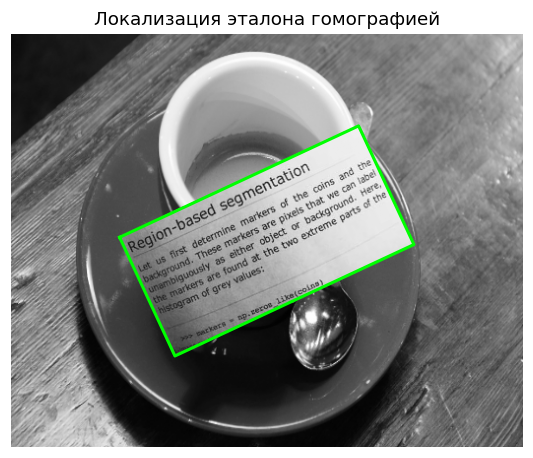

OpenCV inliers: 155
Средняя ошибка углов | своя H: 0.18 px | OpenCV: 0.18 px


In [13]:
def localize_poster(template_img, scene_img, ratio=0.75, tau=3.0):
    """Полный конвейер L06→L07: SIFT → ratio → RANSAC-гомография → контур."""
    t = to_gray_u8(template_img)
    s = to_gray_u8(scene_img)
    sift_local = cv2.SIFT_create(nfeatures=800)
    k1, d1 = sift_local.detectAndCompute(t, None)
    k2, d2 = sift_local.detectAndCompute(s, None)
    if d1 is None or d2 is None or len(d2) < 2:
        raise ValueError('Недостаточно дескрипторов для ratio test.')
    knn_local = cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1, d2, k=2)
    goods = [pair[0] for pair in knn_local
             if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance]
    if len(goods) < 4:
        raise ValueError('После ratio test осталось меньше четырёх пар.')
    p1 = np.float64([k1[m.queryIdx].pt for m in goods])
    p2 = np.float64([k2[m.trainIdx].pt for m in goods])
    H, mask = ransac_homography(p1, p2, tau=tau)
    hh, ww = t.shape
    contour = apply_H(H, np.array([[0, 0], [ww - 1, 0], [ww - 1, hh - 1], [0, hh - 1]], dtype=np.float64))
    return {
        "H": H,
        "n_matches": len(goods),
        "n_inliers": int(mask.sum()),
        "contour_scene": contour,
    }


result = localize_poster(template, scene)
print("пар:", result["n_matches"], "| inliers:", result["n_inliers"])
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(scene, cmap="gray")
c = result["contour_scene"]
ax.plot(*np.vstack([c, c[:1]]).T, "lime", lw=2)
ax.set_title("Локализация эталона гомографией"); ax.axis("off"); plt.show()

H_cv, mask_cv = cv2.findHomography(pts1, pts2, cv2.RANSAC, 3.0)
if H_cv is not None:
    c_cv = apply_H(H_cv, contour)
    print("OpenCV inliers:", int(mask_cv.sum()))
    print(f"Средняя ошибка углов | своя H: {np.linalg.norm(c - c_true, axis=1).mean():.2f} px"
          f" | OpenCV: {np.linalg.norm(c_cv - c_true, axis=1).mean():.2f} px")
else:
    print("OpenCV не нашёл гомографию.")


## Что важно вынести с практики

- пары SIFT — вход; ответ сцены — **одна модель** преобразования плоскости;
- однородные координаты превращают сдвиг/поворот/аффин/гомографию в умножение на $3\times 3$;
- аффин — МНК; гомография — DLT + нормализация Хартли; минимум 4 пары;
- RANSAC спасает от выбросов matching'а; порог $\tau$ и минимальная выборка критичны;
- warping делают **обратным** + интерполяция; 4 угла документа → выравнивание без RANSAC;
- мост дальше: панорама (чистый поворот камеры), калибровка (много гомографий плоскости).
